# 4. Spatial structure: where the stone is struck

This notebook uses the **actual position** of the zones on the stone (taken from the zone map of the 3D model) to
answer question Q4 of the article: *does the acoustic response have a spatial structure?*

1. Coordinates of the 24 zones in metres and distance of each one to the outline of the stone.
2. Do nearby zones sound alike? (Mantel test and Moran's index).
3. Does the timbre depend on whether the stone is struck near the edge or in the interior?
4. Maps of which modes are excited at each point.

It uses the strikes of the **characterisation set** (notebook 01, section 1.3).

**Inputs:** `data/geometry/strike_zone_map.png`, the WAV files, `intermediate/strikes.csv` and `intermediate/features.csv`
(notebook 01). **Outputs:** `tables/t04_zone_coordinates.csv` (equal to `data/geometry/zone_coordinates.csv`),
`tables/t04_*.csv`, figures `fig04*`.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # folder with config.py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import config as C
warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.4})
pd.set_option("display.precision", 2)

from scipy import signal, stats, ndimage
from scipy.io import wavfile
from scipy.spatial.distance import pdist, squareform
import matplotlib.image as mpimg
warnings.filterwarnings("ignore", category=wavfile.WavFileWarning)
FS = C.FS
rng = np.random.default_rng(C.SEED)

## 4.1 Zone coordinates

The coordinates of the 24 zones (`data/geometry/zone_coordinates.csv`) were measured on the top view of the 3D model
(`data/geometry/strike_zone_map.png`): the centre of each marker was located on the map, and the outline of the stone
was separated from the white background. Its length (856 pixels) corresponds to the **2.40 m** measured in the field,
which gives a scale of 2.8 mm per pixel; with that scale the width is 1.03 m, consistent with the ~1.05 m measured. The
distance of each zone to the edge is its distance to that outline.

> It is a **plan projection**: the zones on the side (Z1–Z10) lie on the outline, and the distance to the edge is the
> distance to the outline seen from above.

The outline is recomputed here from the map only to draw it in the figures.

In [2]:
img = mpimg.imread(C.ZONE_MAP)[..., :3]
marks = ndimage.binary_dilation(img.max(-1) < 0.12, iterations=2)       # black markers, numbers and north arrow
m = ndimage.binary_opening((img.min(-1) <= 0.93) & ~marks, iterations=2) # without background or marks
lab, n = ndimage.label(m)
stone = lab == np.argmax(ndimage.sum(m, lab, range(1, n + 1))) + 1
stone = ndimage.binary_fill_holes(ndimage.binary_closing(stone, np.ones((3, 3)), iterations=10))
ys, xs = np.where(stone)
SCALE = 2.40 / (xs.max() - xs.min())                                     # m per pixel
zc = pd.read_csv(C.COORDINATES)
zc.to_csv(C.TABLES / "t04_zone_coordinates.csv", index=False)
print(f"Scale: {SCALE*1000:.2f} mm/pixel | outline {2.40:.2f} × {(ys.max()-ys.min())*SCALE:.2f} m")
zc.round(2).set_index("zone").T

Scale: 2.80 mm/pixel | outline 2.40 × 1.03 m


zone,1,2,3,4,5,6,7,8,9,10,...,15,16,17,18,19,20,21,22,23,24
x_m,0.04,0.20,0.35,0.54,0.82,1.24,1.65,1.96,2.18,2.32,...,1.82,1.68,1.55,1.38,1.26,1.16,0.96,0.65,0.54,0.32
y_m,0.29,0.35,0.14,0.14,0.13,0.09,0.08,0.13,0.19,0.23,...,0.86,0.43,0.72,0.87,0.44,0.74,0.92,0.49,0.63,0.51
edge_distance_m,0.03,0.12,0.09,0.09,0.09,0.08,0.08,0.08,0.13,0.07,...,0.00,0.42,0.19,0.06,0.43,0.24,0.08,0.24,0.06,0.08


## 4.2 Mean spectral features of each zone

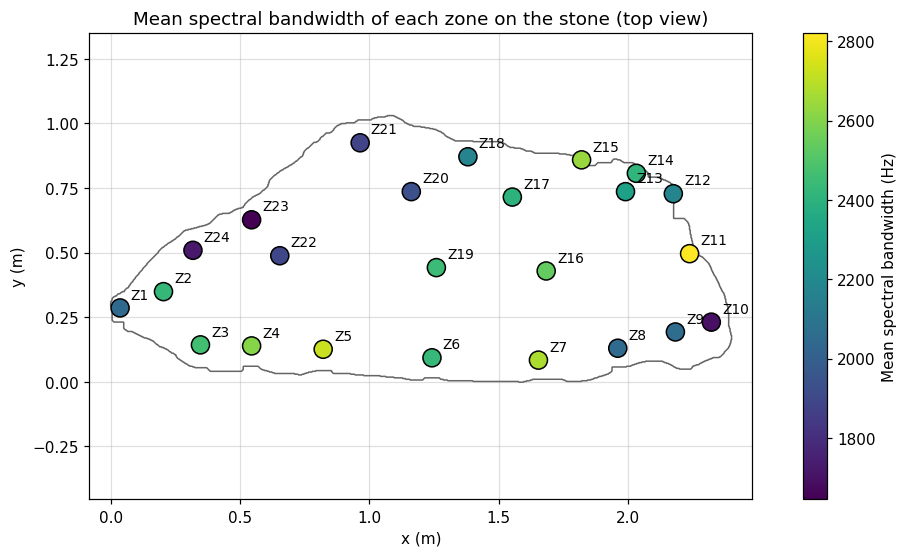

In [3]:
fg = pd.read_csv(C.INTERMEDIATE / "features.csv")
fg = fg[fg.set == "characterisation"]   # characterisation set
rz = fg.groupby("zone").agg(**{f"{c}_{s}": (c, s) for c in ["spectral_centroid", "spectral_bandwidth"] for s in ("mean", "std")},
                            **{f"mfcc_{i}_mean": (f"mfcc_{i}", "mean") for i in range(4)}).reset_index()
zc = zc.merge(rz, on="zone")
outline = lambda ax: ax.contour(np.arange(img.shape[1]) * SCALE - xs.min() * SCALE, ys.max() * SCALE - np.arange(img.shape[0]) * SCALE,
                                stone, [0.5], colors="0.4", linewidths=1)
fig, ax = plt.subplots(figsize=(12, 5.5))
outline(ax)
sc = ax.scatter(zc.x_m, zc.y_m, s=140, c=zc.spectral_bandwidth_mean, cmap="viridis", edgecolor="k", zorder=3)
for _, r in zc.iterrows():
    ax.annotate(f"Z{int(r.zone)}", (r.x_m, r.y_m), textcoords="offset points", xytext=(7, 6), fontsize=9)
ax.set_aspect("equal"); ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)"); fig.colorbar(sc, label="Mean spectral bandwidth (Hz)")
ax.set_title("Mean spectral bandwidth of each zone on the stone (top view)")
plt.savefig(C.FIGURES / "fig04a_bandwidth_map.png", dpi=150, bbox_inches="tight"); plt.show()

## 4.3 Do nearby zones sound alike?

Two permutation tests (no normality assumptions):

* **Mantel test:** Spearman correlation between the physical distance of each pair of zones and their acoustic
  distance. The zones are permuted 4999 times to see how often chance gives an equal or larger correlation.
* **Moran's index:** spatial autocorrelation of a variable. Neighbours = zones less than 0.5 m apart (≈ 4.8 neighbours
  per zone). I > 0 means that neighbouring zones have similar values.

In [4]:
D = squareform(pdist(zc[["x_m", "y_m"]]))
def mantel(A, B, n=4999):
    iu = np.triu_indices_from(A, 1); r0 = stats.spearmanr(A[iu], B[iu])[0]
    larger = sum(stats.spearmanr(A[iu], B[np.ix_(p, p)][iu])[0] >= r0 for p in (rng.permutation(len(B)) for _ in range(n)))
    return r0, (larger + 1) / (n + 1)
def moran(v, W, n=4999):
    v = v - v.mean(); k = len(v) / W.sum()
    I = k * (v @ W @ v) / (v @ v)
    sims = np.array([k * (p @ W @ p) / (p @ p) for p in (rng.permutation(v) for _ in range(n))])
    return I, (np.sum(sims >= I) + 1) / (n + 1)
standardise = lambda X: (X - X.mean()) / X.std()

For the modal content of each zone, the amplitude of the 13 global modes relative to the highest peak of the strike
(dB) is measured in the long window of each strike (notebook 03), and the median over the strikes of the zone is taken.

In [5]:
MODES = pd.read_csv(C.TABLES / "t03_mode_catalogue.csv").mode_Hz.tolist()   # catalogue of notebook 03 (13 modes)
strikes = pd.read_csv(C.INTERMEDIATE / "strikes.csv")
strikes = strikes[strikes.set == "characterisation"].reset_index(drop=True)   # characterisation set
bh, ah = signal.butter(C.FILTER_ORDER, C.HIGHPASS_HZ / (0.5 * FS), btype="high")
bf, af = signal.butter(4, 4000 / (0.5 * FS), btype="high")
sig, onsets = {}, {}
for w in strikes.file.unique():
    _, x = wavfile.read(C.AUDIO / w); xf = signal.filtfilt(bh, ah, x.astype(np.float32).mean(axis=1))
    env = signal.convolve(np.abs(signal.filtfilt(bf, af, xf)), np.ones(96) / 96, "same")
    onsets[w] = signal.find_peaks(env, height=15 * 1.4826 * np.median(env), distance=int(0.15 * FS))[0]; sig[w] = xf
N = 2 ** 18; f = np.fft.rfftfreq(N, 1 / FS); band = (f > C.HIGHPASS_HZ) & (f < 3000)
mode_mask = np.zeros_like(f, bool)
for mo in MODES:
    mode_mask |= np.abs(f - mo) < 5
rows = []
for _, r in strikes.iterrows():
    i = int(r.i_peak); o = onsets[r.file]; nxt = o[o > i + int(0.1 * FS)]
    L = int(min(((nxt[0] if len(nxt) else len(sig[r.file])) - i) / FS - 0.02, 2.0) * FS)
    X = np.abs(np.fft.rfft(sig[r.file][i:i + L] * np.hanning(L), N))
    row = {"zone": r.zone, "modal_purity": (X[mode_mask & band] ** 2).sum() / (X[band] ** 2).sum()}
    Xn = X / X[band].max()
    row.update({f"A{round(mo)}": 20 * np.log10(Xn[(f > mo - 6) & (f < mo + 6)].max()) for mo in MODES})
    rows.append(row)
amp = pd.DataFrame(rows).groupby("zone").median()
amp.round(2).to_csv(C.TABLES / "t04_modal_amplitude_per_zone.csv")
zc = zc.merge(amp[["modal_purity"]], left_on="zone", right_index=True)
amp.drop(columns="modal_purity").round(0).T

zone,1,2,3,4,5,6,7,8,9,10,...,15,16,17,18,19,20,21,22,23,24
A385,-6.0,0.0,-4.0,-13.0,-4.0,0.0,-3.0,-13.0,-10.0,-2.0,...,-3.0,-14.0,-3.0,-9.0,0.0,-1.0,-6.0,-7.0,-9.0,-26.0
A600,-31.0,-24.0,-5.0,0.0,-13.0,-25.0,-11.0,-2.0,0.0,0.0,...,-13.0,0.0,-7.0,0.0,-10.0,-30.0,-12.0,0.0,0.0,0.0
A759,-9.0,-19.0,-24.0,-4.0,-3.0,-11.0,-3.0,-3.0,-32.0,-16.0,...,-21.0,-36.0,-8.0,-17.0,-13.0,-16.0,0.0,-9.0,-16.0,-41.0
A849,0.0,-3.0,-20.0,-3.0,0.0,-5.0,-0.0,0.0,-39.0,-8.0,...,-24.0,-26.0,-7.0,-15.0,-24.0,0.0,-19.0,-13.0,-1.0,-48.0
A970,-30.0,-33.0,0.0,-2.0,-29.0,-28.0,-5.0,-33.0,-14.0,-10.0,...,-4.0,-13.0,-14.0,-8.0,-11.0,-38.0,-7.0,-10.0,-2.0,-15.0
A1260,-25.0,-34.0,-39.0,-25.0,-43.0,-19.0,-26.0,-26.0,-27.0,-44.0,...,-27.0,-14.0,-23.0,-23.0,-37.0,-14.0,-1.0,-34.0,-5.0,-52.0
A1299,-46.0,-42.0,-24.0,-27.0,-43.0,-42.0,-15.0,-19.0,-47.0,-25.0,...,-27.0,-13.0,-30.0,-33.0,-25.0,-38.0,-31.0,-31.0,-24.0,-42.0
A1349,-30.0,-37.0,-5.0,-2.0,-29.0,-2.0,-17.0,-6.0,-19.0,-26.0,...,-19.0,-26.0,-11.0,-13.0,-17.0,-17.0,-21.0,-31.0,-24.0,-32.0
A1389,-13.0,-20.0,-30.0,-20.0,-24.0,-25.0,-21.0,-24.0,-33.0,-18.0,...,-35.0,-33.0,-18.0,-31.0,-24.0,-10.0,-39.0,-46.0,-41.0,-36.0
A1645,-46.0,-43.0,-32.0,-40.0,-18.0,-13.0,-24.0,-22.0,-22.0,-17.0,...,-16.0,-42.0,-38.0,-34.0,-19.0,-21.0,-44.0,-31.0,-20.0,-11.0


In [6]:
res = []
for name, X in [("Timbre (8 features per zone)", standardise(zc[C.ZONE_FEATURES].values)),
                ("Modal content (13 amplitudes, dB)", amp.loc[zc.zone].drop(columns="modal_purity").values)]:
    r, p = mantel(D, squareform(pdist(X)))
    res.append({"test": "Mantel", "variable": name, "statistic": r, "p": p})
W = ((D < 0.5) & (D > 0)).astype(float)
for c, name in [("spectral_centroid_mean", "Mean centroid"), ("spectral_bandwidth_mean", "Mean bandwidth"),
                ("spectral_centroid_std", "s.d. of the centroid"), ("modal_purity", "Modal purity")]:
    I, p = moran(zc[c].values, W)
    res.append({"test": "Moran (neighbours < 0.5 m)", "variable": name, "statistic": I, "p": p})
for c in amp.columns.drop("modal_purity"):
    I, p = moran(amp.loc[zc.zone, c].values, W)
    res.append({"test": "Moran (neighbours < 0.5 m)", "variable": f"Amplitude of the {c[1:]} Hz mode", "statistic": I, "p": p})
res = pd.DataFrame(res); res.to_csv(C.TABLES / "t04_spatial_autocorrelation.csv", index=False)
res.style.format({"statistic": "{:+.2f}", "p": "{:.3f}"}).hide(axis="index")

test,variable,statistic,p
Mantel,Timbre (8 features per zone),+0.04,0.214
Mantel,"Modal content (13 amplitudes, dB)",+0.12,0.045
Moran (neighbours < 0.5 m),Mean centroid,-0.11,0.679
Moran (neighbours < 0.5 m),Mean bandwidth,+0.06,0.172
Moran (neighbours < 0.5 m),s.d. of the centroid,+0.00,0.323
Moran (neighbours < 0.5 m),Modal purity,+0.32,0.008
Moran (neighbours < 0.5 m),Amplitude of the 385 Hz mode,+0.03,0.217
Moran (neighbours < 0.5 m),Amplitude of the 600 Hz mode,-0.02,0.372
Moran (neighbours < 0.5 m),Amplitude of the 759 Hz mode,-0.16,0.851
Moran (neighbours < 0.5 m),Amplitude of the 849 Hz mode,-0.19,0.931


**Reading.** See the table: the spatial structure appears in the **modal purity** (neighbouring zones alike, Moran)
and, more weakly, in the set of modal amplitudes (Mantel), but not in the mean spectral features, and no individual
modal amplitude is autocorrelated on a 0.5 m scale. This is expected if the nodal lines of the modes are closer
together than the zones: with 24 points about 0.3 m apart **the mode shapes cannot be reconstructed**, only the zones
where each mode is most excited.

## 4.4 Edge versus interior

Does the timbre depend on the distance to the outline? Besides the centroid and the bandwidth, the **modal purity** is
used: the fraction of the strike energy (300–3000 Hz) that lies in the 13 global modes (±5 Hz). Close to 1 = the
strike sets the whole stone ringing; low values = a local or broadband response.

variable,spearman_rho,p
Mean centroid,+0.05,0.8306
Mean bandwidth,-0.00,0.9984
s.d. of the centroid,-0.25,0.2302
s.d. of the bandwidth,-0.20,0.3593
Modal purity,+0.30,0.1567


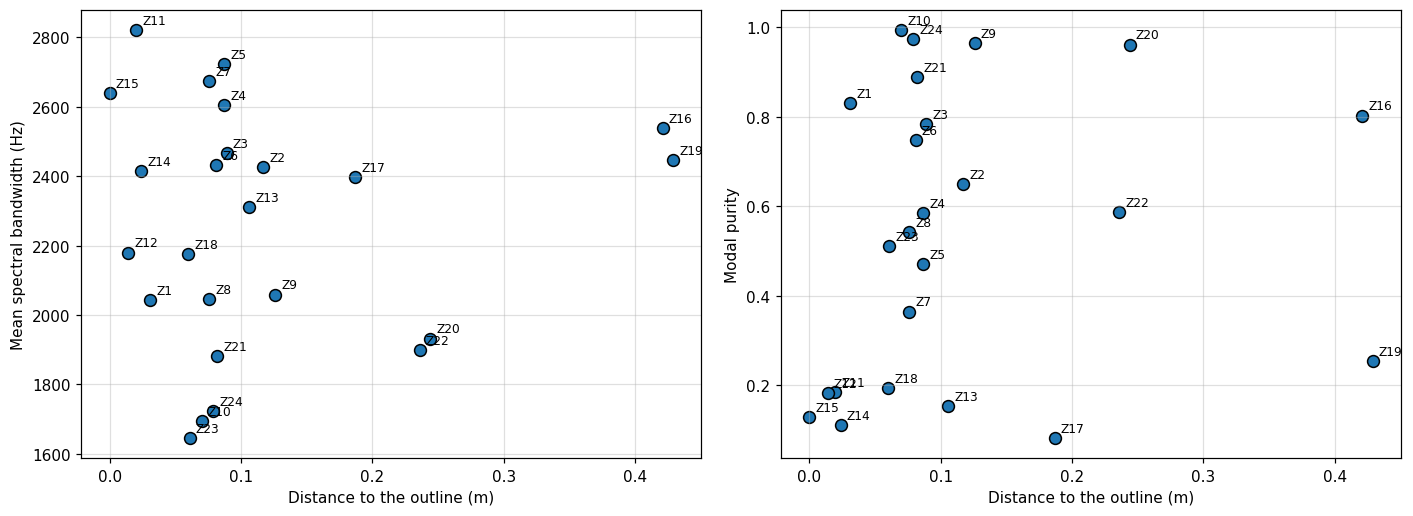

In [7]:
edge = []
for c, name in [("spectral_centroid_mean", "Mean centroid"), ("spectral_bandwidth_mean", "Mean bandwidth"),
                ("spectral_centroid_std", "s.d. of the centroid"), ("spectral_bandwidth_std", "s.d. of the bandwidth"),
                ("modal_purity", "Modal purity")]:
    rho, p = stats.spearmanr(zc.edge_distance_m, zc[c])
    edge.append({"variable": name, "spearman_rho": rho, "p": p})
edge = pd.DataFrame(edge); edge.to_csv(C.TABLES / "t04_edge_vs_timbre.csv", index=False)
display(edge.style.format({"spearman_rho": "{:+.2f}", "p": "{:.4f}"}).hide(axis="index"))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
for a, c, name in [(ax[0], "spectral_bandwidth_mean", "Mean spectral bandwidth (Hz)"), (ax[1], "modal_purity", "Modal purity")]:
    a.scatter(zc.edge_distance_m, zc[c], s=60, color="C0", edgecolor="k")
    for _, r in zc.iterrows():
        a.annotate(f"Z{int(r.zone)}", (r.edge_distance_m, r[c]), textcoords="offset points", xytext=(4, 4), fontsize=8)
    a.set_xlabel("Distance to the outline (m)"); a.set_ylabel(name)
plt.tight_layout(); plt.savefig(C.FIGURES / "fig04b_edge_vs_timbre.png", dpi=150, bbox_inches="tight"); plt.show()

**Reading.** See the table: no feature depends on the distance to the outline.

The zones were not laid out to test this question: 19 of them lie within 13 cm of the edge and only five (Z16, Z17,
Z19, Z20, Z22) are 19–43 cm from it. The next cell compares the two groups directly (Mann–Whitney test). With only
five interior zones the comparison has little power (computed below): it can only detect a large, consistent
difference, and a moderate edge effect could go unnoticed.

The stone rests near its centre on a larger block, with free overhangs at both ends (`data/geometry` and the 3D
model). The edge was expected to sound purer for two reasons, which the data do not confirm but cannot rule out:

* in a plate with free edges, the edges are antinodes of many bending modes, so a strike at the edge excites them
  more efficiently;
* the zones in the interior of the upper face lie over the support or close to it: part of the strike energy is
  transmitted to the block below and more broadband contact noise appears.

In [8]:
zc["position"] = np.where(zc.edge_distance_m < 0.15, "edge", "interior")
ei = []
for c, name in [("modal_purity", "Modal purity"), ("spectral_bandwidth_mean", "Mean bandwidth (Hz)"),
                ("spectral_centroid_mean", "Mean centroid (Hz)")]:
    e_, i_ = zc[zc.position == "edge"][c], zc[zc.position == "interior"][c]
    ei.append({"variable": name, "edge_n": len(e_), "edge_median": e_.median(), "edge_min": e_.min(), "edge_max": e_.max(),
               "interior_n": len(i_), "interior_median": i_.median(), "interior_min": i_.min(), "interior_max": i_.max(),
               "mann_whitney_p": stats.mannwhitneyu(e_, i_).pvalue})
ei = pd.DataFrame(ei); ei.to_csv(C.TABLES / "t04_edge_vs_interior.csv", index=False)
inner = zc[zc.position == "interior"]
print("Interior zones:", ", ".join(f"Z{int(r.zone)} ({100 * r.edge_distance_m:.0f} cm)" for _, r in inner.iterrows()))
print(f"Edge zones: {(zc.position == 'edge').sum()}, all within {100 * zc[zc.position == 'edge'].edge_distance_m.max():.0f} cm of the edge")
# power of the comparison: Mann–Whitney with 19 and 5 zones, normal data shifted by d standard deviations
rng_p = np.random.default_rng(C.SEED)
power = {d: np.mean([stats.mannwhitneyu(rng_p.normal(0, 1, (zc.position == "edge").sum()),
                                        rng_p.normal(d, 1, (zc.position == "interior").sum())).pvalue < 0.05 for _ in range(4000)])
         for d in [0.5, 1.0, 1.5, 2.0]}
print("Power to detect a difference of d standard deviations (alpha = 0.05):", {d: round(float(v), 2) for d, v in power.items()})
ei.round(2)

Interior zones: Z16 (42 cm), Z17 (19 cm), Z19 (43 cm), Z20 (24 cm), Z22 (24 cm)
Edge zones: 19, all within 13 cm of the edge


Power to detect a difference of d standard deviations (alpha = 0.05): {0.5: 0.14, 1.0: 0.42, 1.5: 0.77, 2.0: 0.94}


,variable,edge_n,edge_median,edge_min,edge_max,interior_n,interior_median,interior_min,interior_max,mann_whitney_p
0,Modal purity,19,0.54,0.11,0.99,5,0.59,0.08,0.96,1.00
1,Mean bandwidth (Hz),19,2311.85,1645.81,2820.01,5,2398.37,1897.51,2538.81,0.89
2,Mean centroid (Hz),19,1627.94,1491.37,1966.79,5,1640.01,1436.97,1762.07,0.58


## 4.5 Where each mode is excited
Size and colour of the circle = relative amplitude of the mode in that zone (dB relative to the highest peak of the strike). The six most frequent modes are shown; there is no interpolation between zones (see 4.3).

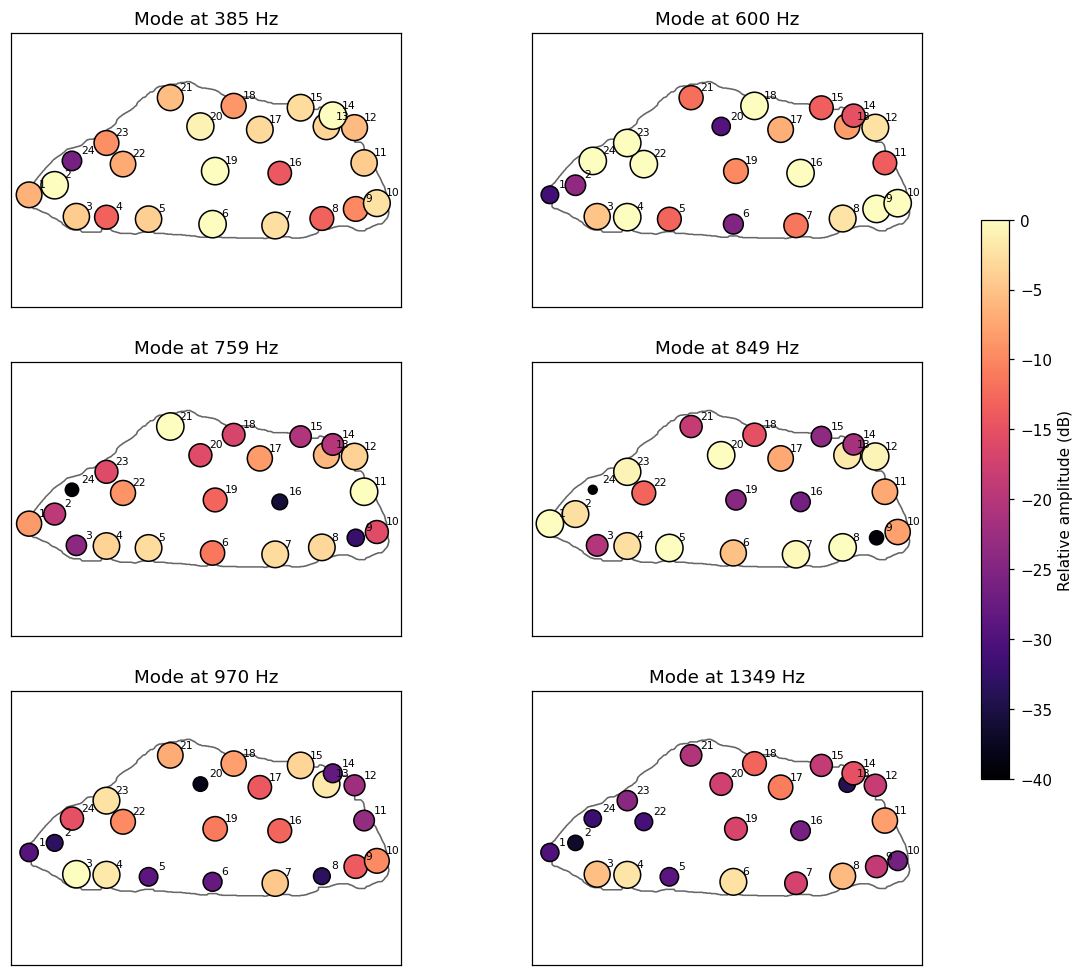

In [9]:
show = ["A385", "A600", "A759", "A849", "A970", "A1349"]
fig, axs = plt.subplots(3, 2, figsize=(14, 11))
for a, c in zip(axs.flat, show):
    outline(a)
    v = amp.loc[zc.zone, c].values
    sc = a.scatter(zc.x_m, zc.y_m, s=20 + 6 * (v + 50).clip(0), c=v, cmap="magma", vmin=-40, vmax=0, edgecolor="k", zorder=3)
    for _, r in zc.iterrows():
        a.annotate(str(int(r.zone)), (r.x_m, r.y_m), textcoords="offset points", xytext=(6, 5), fontsize=7)
    a.set_aspect("equal"); a.set_title(f"Mode at {c[1:]} Hz"); a.set_xticks([]); a.set_yticks([])
fig.colorbar(sc, ax=axs, shrink=.6, label="Relative amplitude (dB)")
plt.savefig(C.FIGURES / "fig04c_mode_maps.png", dpi=150, bbox_inches="tight"); plt.show()

## Conclusion

With the strikes of the characterisation set:

* The 24 zones have **real coordinates** (`data/geometry/zone_coordinates.csv`).
* **No dependence on the distance to the outline is detected:** neither the mean centroid, nor the mean bandwidth, nor
  the modal purity change with it, and the five interior zones do not differ from the 19 edge zones (table
  `t04_edge_vs_interior.csv`). There are very pure edge zones (Z9, Z10, Z24) and dull ones (Z11, Z12, Z14, Z15), and
  pure (Z16, Z20) and dull (Z17, Z19) interior zones. With only five interior zones this comparison has little power.
* **The modal purity does have a spatial structure:** neighbouring zones have similar purities (Moran's I), and the
  amplitudes of the 13 modes are somewhat more alike in nearby zones (Mantel test). The mean spectral features show no
  autocorrelation.
* With one zone every ~0.3 m **the mode shapes cannot be mapped**; the maps only show where each mode is most excited.

**Limitations:** the map is a plan projection of a 3D model and the side zones lie on the outline; the position of the
microphone was not fixed and may change the relative amplitudes of the modes through directivity.